# 46-923, Fall 2026: Homework #4

Data: WRDS Millisecond Intraday Indicators for 50 randomly chosen S&P 500 stocks, 2025.

In [1]:
import warnings
warnings.filterwarnings(action='ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import scale
from sklearn.decomposition import PCA, KernelPCA
from sklearn import manifold
from sklearn.manifold import TSNE

## Data

The 50 stocks are drawn at random from the stocks that were in the S&P 500 for all of 2025 and trade under a plain TAQ symbol. The data are downloaded on the first run and saved to `hw4_iid_2025.csv`. Set `WRDS_USERNAME` to your own WRDS login.

In [2]:
WRDS_USERNAME = "ryez"

In [3]:
if os.path.exists("hw4_iid_2025.csv"):
    df = pd.read_csv("hw4_iid_2025.csv", parse_dates=["date"])
else:
    import wrds
    db = wrds.Connection(wrds_username=WRDS_USERNAME)

    members = db.raw_sql("""
        WITH Continuous_Members AS (
            SELECT permno
            FROM crsp.dsp500list_v2
            WHERE mbrstartdt <= '2025-01-01'
              AND mbrenddt >= '2025-12-31'
        )
        SELECT DISTINCT s.ticker
        FROM Continuous_Members AS m
        INNER JOIN crsp.stksecurityinfohist AS s
            ON m.permno = s.permno
            AND s.secinfostartdt <= '2025-12-31'
            AND s.secinfoenddt >= '2025-12-31'
    """)

    tick_sql = ", ".join(f"'{t}'" for t in members["ticker"])
    in_taq = db.raw_sql(f"""
        SELECT DISTINCT sym_root
        FROM taqmsec.wrds_iid_2025
        WHERE date = '2025-12-31'
            AND sym_root IN ({tick_sql})
            AND (sym_suffix IS NULL OR sym_suffix = '')
        ORDER BY sym_root
    """)

    tickers = in_taq["sym_root"].sample(50, random_state=0)

    tick_sql = ", ".join(f"'{t}'" for t in tickers)
    df = db.raw_sql(f"""
        SELECT *
        FROM taqmsec.wrds_iid_2025
        WHERE sym_root IN ({tick_sql})
            AND (sym_suffix IS NULL OR sym_suffix = '')
    """, date_cols=["date"])
    db.close()
    df.to_csv("hw4_iid_2025.csv", index=False)

df.shape, df["sym_root"].nunique()

((12500, 208), 50)

## Variables

These are 15 trade counts and dollar volumes by trade type. The trade types are subsets of the same day's trades, and counts and dollars are linked by dollars = trades × shares per trade × price, so the variables should be highly related.

In [4]:
V = ["total_n_trades_m", "total_dollar_m",
     "n_oddlot_trade", "oddlot_dollar",
     "n_iso_trade", "iso_dollar",
     "total_trade_retail", "total_dv_retail",
     "total_trade_inst20k", "total_dv_inst20k",
     "total_trade_inst50k", "total_dv_inst50k",
     "n_outside_nbbo_trade",
     "total_dollar_b", "total_dollar_a"]

## Preparation

A blank value means there were no trades of that type that day (e.g. no pre-market trades), so blanks are set to 0. Each variable is then transformed with $\log_{10}(1+x)$ (all are right-skewed and some are 0) and scaled. The analysis uses a random sample of 60 days per stock.

In [5]:
sub_idx = (df.groupby("sym_root", group_keys=False)
             .sample(60, random_state=0).index)
sub = df.loc[sub_idx].reset_index(drop=True)
Z = scale(np.log10(1 + sub[V].fillna(0)))
Z.shape

(3000, 15)

## Number of Dimensions

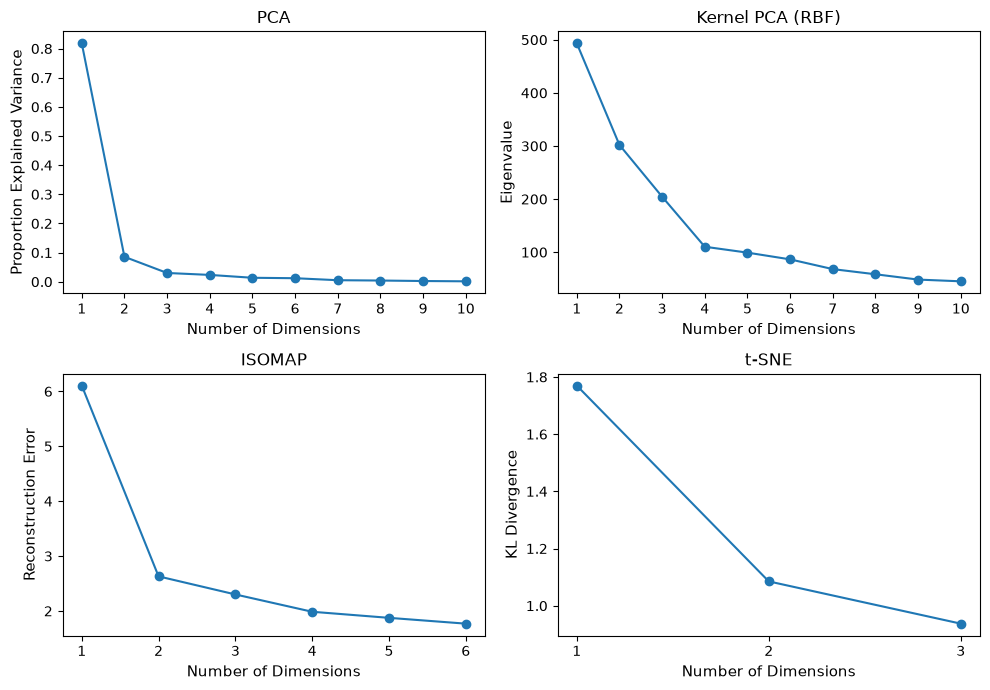

In [6]:
pcaout = PCA(n_components=10).fit(Z)
kpca = KernelPCA(n_components=10, kernel="rbf", gamma=0.1).fit(Z)
iso_err = [manifold.Isomap(n_neighbors=10, n_components=d).fit(Z)
           .reconstruction_error() for d in range(1, 7)]
tsne_kl = [TSNE(n_components=d, random_state=0).fit(Z).kl_divergence_
           for d in [1, 2, 3]]

fig, ax = plt.subplots(2, 2, figsize=[10, 7])
ax = ax.flatten()
ax[0].plot(range(1, 11), pcaout.explained_variance_ratio_, marker="o")
ax[0].set_ylabel("Proportion Explained Variance", size=11)
ax[1].plot(range(1, 11), kpca.eigenvalues_, marker="o")
ax[1].set_ylabel("Eigenvalue", size=11)
ax[2].plot(range(1, 7), iso_err, marker="o")
ax[2].set_ylabel("Reconstruction Error", size=11)
ax[3].plot([1, 2, 3], tsne_kl, marker="o")
ax[3].set_ylabel("KL Divergence", size=11)
titles = ["PCA", "Kernel PCA (RBF)", "ISOMAP", "t-SNE"]
for a, t in zip(ax, titles):
    a.set_title(t)
    a.set_xlabel("Number of Dimensions", size=11)
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

PCA, ISOMAP and t-SNE flatten after two dimensions; two PCA components explain 90% of the variance. The Kernel PCA eigenvalues decline more slowly and level off only after about four, so two Kernel PCA dimensions keep less of its structure. We use two dimensions for all four methods so that they can be compared in the same plots.

## Two-Dimensional Representations

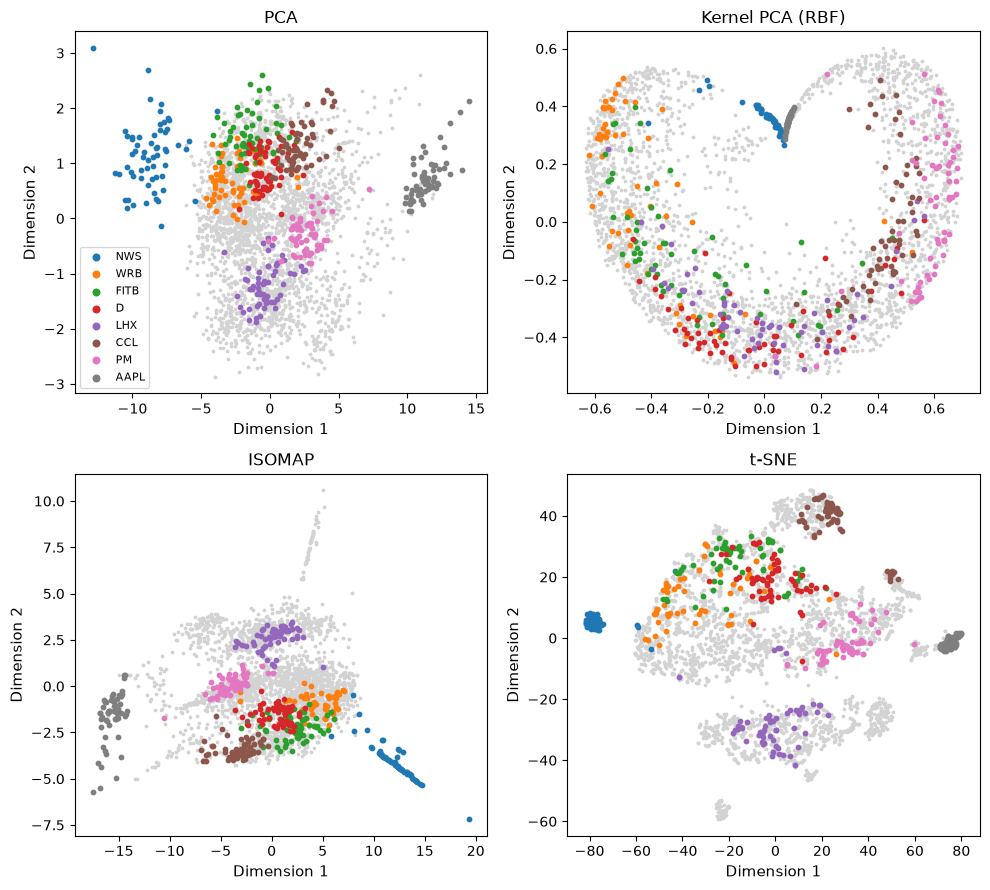

In [7]:
X_pca = PCA(n_components=2).fit_transform(Z)
X_kpca = KernelPCA(n_components=2, kernel="rbf", gamma=0.1).fit_transform(Z)
X_iso = manifold.Isomap(n_neighbors=10, n_components=2).fit_transform(Z)
X_tsne = TSNE(n_components=2, random_state=0).fit_transform(Z)

size = sub.groupby("sym_root")["total_dollar_m"].median().sort_values()
show = list(size.index[np.linspace(0, len(size) - 1, 8).astype(int)])
emb = {"PCA": X_pca, "Kernel PCA (RBF)": X_kpca,
       "ISOMAP": X_iso, "t-SNE": X_tsne}

fig, axes = plt.subplots(2, 2, figsize=[10, 9])
for ax, (name, X) in zip(axes.flatten(), emb.items()):
    other = ~sub["sym_root"].isin(show)
    ax.scatter(X[other, 0], X[other, 1], s=3, color="lightgrey")
    for t in show:
        m = sub["sym_root"] == t
        ax.scatter(X[m, 0], X[m, 1], s=10, label=t)
    ax.set_title(name)
    ax.set_xlabel("Dimension 1", size=11)
    ax.set_ylabel("Dimension 2", size=11)
axes[0, 0].legend(fontsize=8, markerscale=1.5)
plt.tight_layout()
plt.show()

Eight stocks, spaced evenly by median dollar volume, are highlighted; all other stocks are in grey.

- **t-SNE** separates the stocks best: most highlighted stocks form their own island, and only WRB, FITB and D partly overlap.
- **PCA** and **ISOMAP** separate the smallest (NWS) and largest (AAPL) stocks along dimension 1, but the mid-sized stocks overlap.
- **Kernel PCA** bends the data into a curve, places the two extremes (NWS and AAPL) next to each other, and mixes the remaining stocks.

The 15 variables compress well to two dimensions by any of these methods. 